In [3]:
%load_ext autoreload
%autoreload 2

In [2]:
from mltools.seg.dataset import SegDataset
from mltools import PROCESSED_DIR
from pathlib import Path

dataset = SegDataset(Path(PROCESSED_DIR) / "logs_Min256", cache_amount=0)

/home/matic/mltools/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Caching data...: 0it [00:00, ?it/s]


In [ ]:
from matplotlib import pyplot as plt


def show_case(image, mask):

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.title("Image")
    plt.imshow(image)
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.title("Mask")
    plt.imshow(mask, cmap="gray", vmin=0, vmax=1)
    plt.axis("off")

    plt.show()

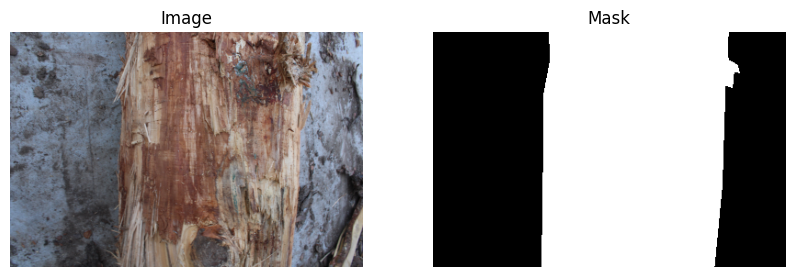

In [4]:
image, mask = dataset[0]
show_case(image, mask)

In [ ]:
import cv2
import numpy as np
from scipy.stats import norm


def apply_vignette(image, mask, amount=0.5):
    """
    Applies a contour-aware vignette.
    amount: 0.0 (no effect) to 1.0 (full mask falloff)
    """
    if amount <= 0 or not np.any(mask):
        return image
    if amount >= 1:
        return image * (mask > 0)

    # mask should be uint8 (0 and 255)
    dist = cv2.distanceTransform(~mask, cv2.DIST_L2, 5)

    # normalize to [0, 1]
    # cv2.normalize(dist, dist, 0, 1.0, cv2.NORM_MINMAX)

    # The kernel size should be proportional to image resolution
    blur_size = int(image.shape[0] * 0.05) | 1  # Must be odd
    vignette_map = cv2.GaussianBlur(dist, (blur_size, blur_size), 0)
    print(blur_size)

    # apply bell curve for falloff control
    scale = min(image.shape[0:2]) * 0.5
    vignette_map = norm.cdf(vignette_map, loc=0, scale=(scale * (1 - amount)))
    vignette_map = 1 - vignette_map
    cv2.normalize(vignette_map, vignette_map, 0, 1.0, cv2.NORM_MINMAX)

    # add channel dimension for broadcasting if image is RGB
    if len(image.shape) == 3:
        vignette_map = vignette_map[:, :, np.newaxis]

    # apply to image
    # ensure image is float for multiplication
    result = (image.astype(np.float32) * vignette_map).astype(np.uint8)

    return result

13


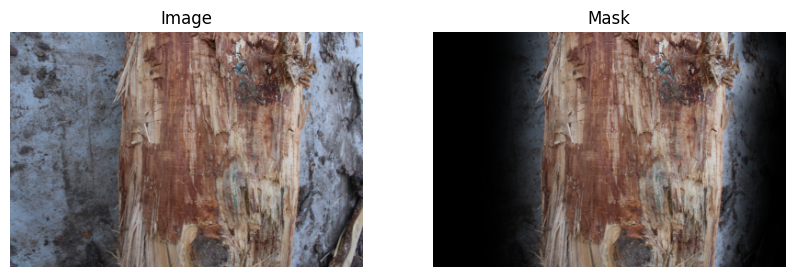

In [6]:
vignette = apply_vignette(image, (mask * 255).astype(np.uint8), amount=0.8)
show_case(image, vignette)
# show_case(vignette, mask)

In [ ]:
import hydra
from mltools.seg.schema import TrainConfig

with hydra.initialize(version_base=None, config_path="../configs"):
    cfg: TrainConfig = hydra.compose(
        config_name="config",
    )

Caching data...: 0it [00:00, ?it/s]


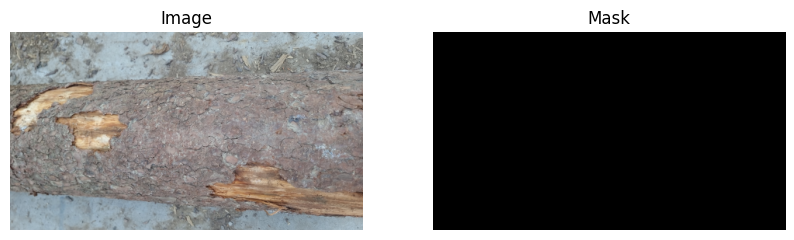

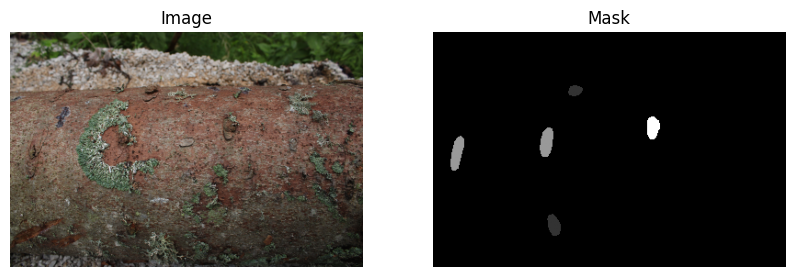

In [ ]:
from mltools.seg.dataset import SegDataset
from mltools import PROCESSED_DIR
from pathlib import Path
from mltools.seg.schema.root import ClassGroupConfig

class_groups = [
    ClassGroupConfig(value=1.0, classes=[1.0]),
    ClassGroupConfig(value=0.6, classes=[0.2, 0.6]),
]
class_groups = None

dataset = SegDataset(
    Path(PROCESSED_DIR) / "knots_Min256", cache_amount=0, class_groups=class_groups
)
for i in range(350, 352):
    image, mask = dataset[i]
    # vignette = apply_vignette(image, (mask * 255).astype(np.uint8), amount=0.8)
    show_case(image, mask)

In [ ]:
from mltools.seg.schema import AugmentationConfig
from mltools.seg.transform.transforms import get_train_transform


def apply_augmentation(image, mask, config: AugmentationConfig):
    transform = get_train_transform(config)
    out = transform(image=image, mask=mask)
    return out["image"], out["mask"]

(3, 3, 1)
(3, 3, 1) (3, 3, 1)
[[[0.2]
  [0.2]
  [1. ]]

 [[0.2]
  [0.2]
  [1. ]]

 [[0.2]
  [0.2]
  [1. ]]]


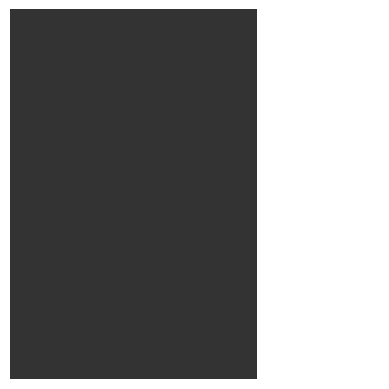

In [ ]:
from mltools.seg.transform.transforms import get_vignette

mask_dummy = np.array([[0, 0, 0], [0, 0.2, 1.0], [0, 0, 0]], dtype=np.float32).reshape(
    3, 3, 1
)
vignette_map = get_vignette(mask_dummy, amount=0.8)
print(vignette_map)
plt.imshow(vignette_map, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()

/home/matic/mltools/src/mltools/seg/transform/transforms.py:101: UserWarning: Using lambda is incompatible with multiprocessing. Consider using regular functions or partial().
  A.Lambda(
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.01058951..1.0724559].


[0.  0.2 0.6 1. ]
(256, 256, 1)
(256, 256, 1) (256, 256, 1)
[0.00000000e+00 4.44091078e-17 8.88182156e-17 ... 5.99992909e-01
 5.99997508e-01 6.00000024e-01]


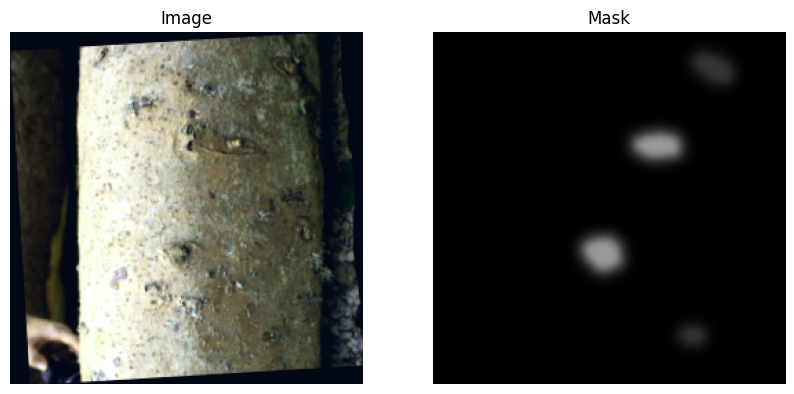

In [ ]:
import numpy as np

cfg.augmentation.mask_vignette_amount = 0.95
image, mask = dataset[344]
print(np.unique(mask))
out_image, out_mask = apply_augmentation(image, mask, cfg.augmentation)
out_image = np.transpose(out_image, (1, 2, 0))  # CHW to HWC
out_mask = np.transpose(out_mask, (1, 2, 0))  # CHW to HWC
print(np.unique(out_mask))
# unnormalize imagenet image for visualization
out_image = (out_image * 0.224) + 0.485
show_case(out_image, out_mask)